# Project 3

Chosen dataset: 2008 U.S. Presidential Election, [documentation](https://vincentarelbundock.github.io/Rdatasets/doc/Stat2Data/Election08.html)
<br>51 observations, 7 variables
<br>binary response variable: ObamaWin	1= Obama (Democrat) wins state in 2008 or 0=McCain (Republican) wins

Variables (51 cases, one per state plus D.C.):
- ```ObamaWin``` (response): 1 if Obama won the state in 2008, 0 if McCain won. Obama won 29 states and McCain won 22, so the response is reasonably balanced.
- ```Income``` (quantitative): per capita income in 2007, in dollars (ranges from about $28,800 to $61,100).
- ```HS``` (quantitative): percent of adults in the state with at least a high school diploma.
- ```BA``` (quantitative): percent of adults with at least a bachelor's degree.
- ```Dem.Rep``` (quantitative): percent of registered voters who are Democrats minus the percent who are Republicans (negative means Republicans have the registration advantage).

All four predictors are quantitative. ```State``` and ```Abr``` are just labels, so they are not used.

In [25]:
install.packages("Stat2Data")
library(Stat2Data)

data("Election08")
View(Election08)

Warning message:
“package ‘Stat2Data’ is not available for this version of R

A version of this package for your version of R might be available elsewhere,
see the ideas at
https://cran.r-project.org/doc/manuals/r-patched/R-admin.html#Installing-packages”


State,Abr,Income,HS,BA,Dem.Rep,ObamaWin
<fct>,<fct>,<int>,<dbl>,<dbl>,<int>,<int>
Alabama,AL,32404,80.4,21.4,-1,0
Alaska,AK,40352,90.5,26.0,-11,0
Arizona,AZ,33029,83.5,25.3,0,0
Arkansas,AR,30060,81.1,19.3,12,0
California,CA,41571,80.2,29.5,19,1
Colorado,CO,41042,88.9,35.0,11,1
Connecticut,CT,54117,88.0,34.7,26,1
Delaware,DE,40608,87.4,26.1,23,1
District of Columbia,DC,61092,85.7,47.5,75,1


In [26]:
# check the balance of the response
table(Election08$ObamaWin)
summary(Election08)


 0  1 
22 29 

         State         Abr         Income            HS              BA       
 Alabama    : 1   AK     : 1   Min.   :28845   Min.   :78.50   Min.   :17.30  
 Alaska     : 1   AL     : 1   1st Qu.:33536   1st Qu.:83.00   1st Qu.:24.20  
 Arizona    : 1   AR     : 1   Median :36047   Median :87.00   Median :25.80  
 Arkansas   : 1   AZ     : 1   Mean   :37642   Mean   :86.00   Mean   :27.15  
 California : 1   CA     : 1   3rd Qu.:40544   3rd Qu.:89.05   3rd Qu.:29.65  
 Colorado   : 1   CO     : 1   Max.   :61092   Max.   :91.20   Max.   :47.50  
 (Other)    :45   (Other):45                                                  
    Dem.Rep          ObamaWin     
 Min.   :-23.00   Min.   :0.0000  
 1st Qu.:  3.00   1st Qu.:0.0000  
 Median : 12.00   Median :1.0000  
 Mean   : 12.31   Mean   :0.5686  
 3rd Qu.: 19.00   3rd Qu.:1.0000  
 Max.   : 75.00   Max.   :1.0000  
                                  

For my single quantitative predictor, I'll use ```income``` per capita income in the state as of 2007 (in dollars)

In [27]:
# (a) Include the summary output using R to estimate the coefficients of this model.
m1 = glm(ObamaWin ~ Income, data = Election08, family = binomial)
summary(m1)


Call:
glm(formula = ObamaWin ~ Income, family = binomial, data = Election08)

Coefficients:
              Estimate Std. Error z value Pr(>|z|)    
(Intercept) -1.243e+01  3.752e+00  -3.311 0.000928 ***
Income       3.494e-04  1.050e-04   3.328 0.000874 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

(Dispersion parameter for binomial family taken to be 1)

    Null deviance: 69.737  on 50  degrees of freedom
Residual deviance: 48.867  on 49  degrees of freedom
AIC: 52.867

Number of Fisher Scoring iterations: 5


In [28]:
# (b) Interpret the slope coefficient (in terms of an odds ratio) and interpret the test for the slope.
b1 = coef(m1)["Income"]
exp(b1)                        # multiplicative change in odds per +$1 of income
exp(b1 * 1000)                 # per +$1,000 of income
coef(summary(m1))["Income", ]  # estimate, SE, z value, p-value

Income 
1.000349

Income 
1.418252

Estimate   Std. Error      z value     Pr(>|z|) 
0.0003494252 0.0001049842 3.3283600169 0.0008735889

The slope is 0.000349, so the odds ratio is e^0.000349 = 1.00035 per dollar. That is easier to read per $1,000: **each additional $1,000 of per capita income multiplies the odds that Obama wins the state by e^0.349 = 1.418**, or about a 42% increase in the odds.

The test for the slope has H0: slope = 0 (income is unrelated to the chance Obama wins) and gives z = 3.328 with p = 0.00087. This is strong evidence that, among states, higher income goes with a higher chance of an Obama win.

In [29]:
# (c) Compute a 95% confidence interval for your slope and use it to find a confidence interval for the odds ratio.
b1_se = coef(summary(m1))["Income", "Std. Error"]
ci_slope = b1 + c(-1, 1) * qnorm(0.975) * b1_se
ci_slope
exp(ci_slope)          # CI for the odds ratio (per $1)
exp(ci_slope * 1000)   # CI for the odds ratio (per $1,000)

[1] 0.0001436599 0.0005551904

[1] 1.000144 1.000555

[1] 1.154491 1.742273

The 95% CI for the slope is 0.000349 ± 1.96(0.000105) = (0.000144, 0.000555).
Exponentiating gives a 95% CI for the odds ratio of (1.000144, 1.000555) per dollar, or **(1.154, 1.742) per $1,000**.

The interval does not include 1. That matters because an odds ratio of 1 means the odds of an Obama win do not change with income (slope = 0). Since 1 is not a plausible value, income is a significant predictor, which agrees with the small p-value above.

In [30]:
# (d) Show (by hand) how to use the fitted model for predicting a couple of typical cases.
b0 = coef(m1)["(Intercept)"]
summary(Election08$Income)

for (x in c(35000, 45000)) {
  logit = b0 + b1 * x
  odds = exp(logit)
  p = odds / (1 + odds)
  cat("Income =", x, " logit =", logit, " odds =", odds, " P(ObamaWin) =", p, "\n")
}

# check against R
predict(m1, newdata = data.frame(Income = c(35000, 45000)), type = "response")

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  28845   33536   36047   37642   40544   61092 

Income = 35000  logit = -0.1952259  odds = 0.8226488  P(ObamaWin) = 0.451348 
Income = 45000  logit = 3.299026  odds = 27.08624  P(ObamaWin) = 0.9643954 


1         2 
0.4513480 0.9643954

The fitted model is log(odds) = -12.43 + 0.0003494(Income). The incomes in the data run from $28,845 to $61,092, with a median of $36,047.

- **Income = $35,000:** logit = -12.43 + 0.0003494(35000) = -0.195, so odds = e^-0.195 = 0.823 and p = 0.823 / 1.823 = **0.451**. A state with this income has about a 45% chance of voting for Obama.
- **Income = $45,000:** logit = 3.299, so odds = e^3.299 = 27.09 and p = 27.09 / 28.09 = **0.964**. A state with this income has about a 96% chance of voting for Obama.

Both match the output of ```predict()```.

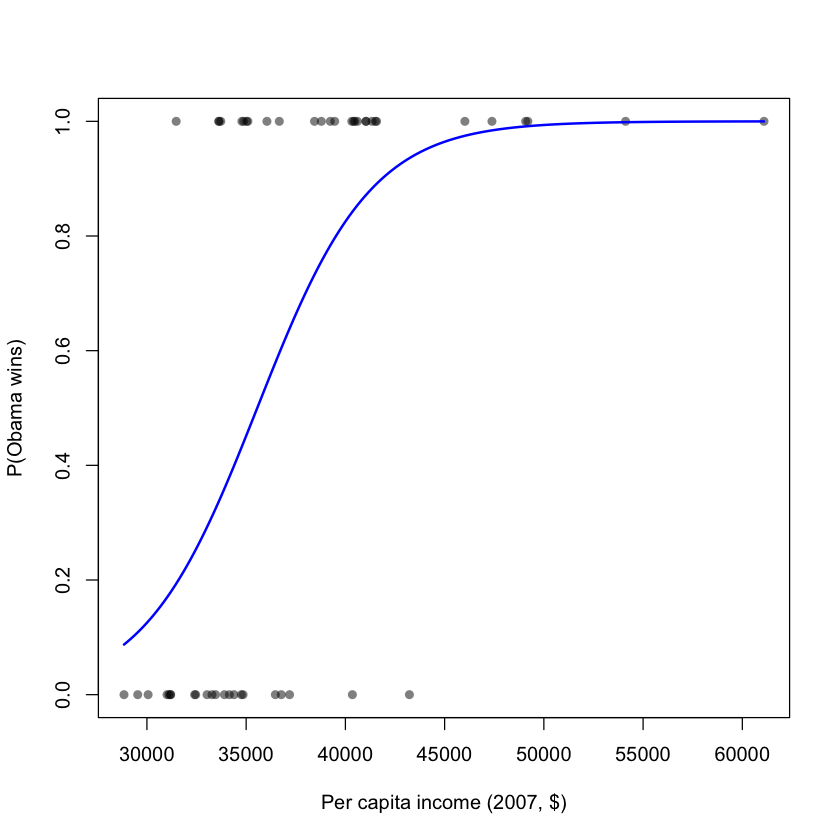

In [31]:
# (e) Include a plot of the logistic fit (with commentary).
plot(ObamaWin ~ Income, data = Election08,
     xlab = "Per capita income (2007, $)", ylab = "P(Obama wins)",
     pch = 16, col = rgb(0, 0, 0, 0.5))
xs = seq(min(Election08$Income), max(Election08$Income), length.out = 200)
lines(xs, predict(m1, data.frame(Income = xs), type = "response"), col = "blue", lwd = 2)

The fitted curve is an increasing S-shape. It crosses 0.5 at an income of about $35,600 (where the logit is 0, 12.43 / 0.0003494) and rises quickly after that, reaching nearly 1 by about $45,000. Low-income states have a probability near 0. The curve follows the data well in the tails, but there is a lot of overlap in the middle, around $33,000 to $42,000, where both Obama and McCain states appear. Income alone cannot separate those states.

In [32]:
# (f) Show how to compute the G-statistic and use it to test the effectiveness of your model.
G = m1$null.deviance - m1$deviance
df = m1$df.null - m1$df.residual
G
df
pchisq(G, df = df, lower.tail = FALSE)  # p-value from the upper tail of chi-square(df)

# check with anova
anova(m1, test = "Chisq")

[1] 20.87035

[1] 1

[1] 4.914431e-06

,Df,Deviance,Resid. Df,Resid. Dev,Pr(>Chi)
,<int>,<dbl>,<int>,<dbl>,<dbl>
NULL,NA,NA,50,69.73719,NA
Income,1,20.87035,49,48.86684,4.914431e-06


G = null deviance - residual deviance = 69.737 - 48.867 = **20.870** on 1 degree of freedom (the model has one predictor more than the constant model).

H0: the slope is 0, so the model is no better than the constant model. Under H0, G follows a chi-square distribution with 1 df, and the p-value is the area above G, ```pchisq(20.87, df = 1, lower.tail = FALSE)``` = 4.9e-06 (the same value appears in the ```anova``` output). We reject H0 and conclude the model with income is effective.

Multiple: Choose your best model using at least two predictors. Try to balance getting a good fit
with keeping the model simple (but use multiple predictors—even if one or all are not very
effective).
(a) Explain briefly the process that led to your choice for a final model. Include summary
output from R for your final model.
(b) As above, show (by hand) how to use the fitted model to predict one typical case.
(c) Comment on the effectiveness of each predictor in the model as well as the overall fit.
Be sure to indicate what value(s) from the output lead to your conclusions. 

For the multiple logistic regression, I'll consider ```Income```, ```HS```, ```BA``` and ```Dem.Rep``` as potential predictors

In [33]:
# (a) Explain briefly the process that led to your choice for a final model. Include summary output from R for your final model.
names(Election08)
full = glm(ObamaWin ~ Income + HS + BA + Dem.Rep, data = Election08, family = binomial)
summary(full)

m2 = glm(ObamaWin ~ Dem.Rep, data = Election08, family = binomial)
m3 = glm(ObamaWin ~ Income + Dem.Rep, data = Election08, family = binomial)
m4 = glm(ObamaWin ~ Income + Dem.Rep + BA, data = Election08, family = binomial)
AIC(m1, m2, m3, m4, full)
anova(m3, full, test = "Chisq")  # do HS and BA add anything to Income + Dem.Rep?

final = m3
summary(final)

[1] "State"    "Abr"      "Income"   "HS"       "BA"       "Dem.Rep"  "ObamaWin"

Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”



Call:
glm(formula = ObamaWin ~ Income + HS + BA + Dem.Rep, family = binomial, 
    data = Election08)

Coefficients:
              Estimate Std. Error z value Pr(>|z|)  
(Intercept) -5.361e+01  3.773e+01  -1.421   0.1554  
Income       6.445e-04  4.828e-04   1.335   0.1819  
HS           1.514e-01  3.894e-01   0.389   0.6973  
BA           5.214e-01  3.947e-01   1.321   0.1865  
Dem.Rep      6.353e-01  2.726e-01   2.331   0.0198 *
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

(Dispersion parameter for binomial family taken to be 1)

    Null deviance: 69.7372  on 50  degrees of freedom
Residual deviance:  9.7252  on 46  degrees of freedom
AIC: 19.725

Number of Fisher Scoring iterations: 10


Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”
Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”


,df,AIC
,<dbl>,<dbl>
m1,2,52.86684
m2,2,31.16692
m3,3,18.92278
m4,4,17.88874
full,5,19.72525


,Resid. Df,Resid. Dev,Df,Deviance,Pr(>Chi)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,48,12.922777,NA,NA,NA
2,46,9.725247,2,3.19753,0.202146



Call:
glm(formula = ObamaWin ~ Income + Dem.Rep, family = binomial, 
    data = Election08)

Coefficients:
              Estimate Std. Error z value Pr(>|z|)  
(Intercept) -3.661e+01  1.751e+01  -2.090   0.0366 *
Income       9.133e-04  4.673e-04   1.954   0.0506 .
Dem.Rep      5.122e-01  2.216e-01   2.312   0.0208 *
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

(Dispersion parameter for binomial family taken to be 1)

    Null deviance: 69.737  on 50  degrees of freedom
Residual deviance: 12.923  on 48  degrees of freedom
AIC: 18.923

Number of Fisher Scoring iterations: 9


I started with all four predictors. In the full model only ```Dem.Rep``` was significant (p = 0.020), and ```HS``` (p = 0.70) was clearly not useful. Residual deviance was only 9.7, and R warned that fitted probabilities of exactly 0 or 1 occurred, which signals the model is nearly separating the two groups.

I then compared smaller models by AIC: Income alone 52.9, Dem.Rep alone 31.2, Income + Dem.Rep 18.9, Income + Dem.Rep + BA 17.9, and all four 19.7. Adding ```HS``` and ```BA``` to Income + Dem.Rep does not significantly improve the fit (G-test, 2 df, p = 0.20), and adding BA only lowers AIC by about 1, with BA itself not significant (p = 0.12).

My final model is **ObamaWin ~ Income + Dem.Rep**. It keeps two predictors, balances fit and simplicity, and has a much lower AIC than either predictor alone.

In [34]:
# (b) As above, show (by hand) how to use the fitted model to predict one typical case.
cf = coef(final)
summary(Election08[, c("Income", "Dem.Rep")])
new = c("(Intercept)" = 1, Income = 36000, Dem.Rep = 12)  # about the median state
logit = sum(cf * new[names(cf)])
p = exp(logit) / (1 + exp(logit))
logit
p

# check against R
predict(final, data.frame(Income = 36000, Dem.Rep = 12), type = "response")

     Income         Dem.Rep      
 Min.   :28845   Min.   :-23.00  
 1st Qu.:33536   1st Qu.:  3.00  
 Median :36047   Median : 12.00  
 Mean   :37642   Mean   : 12.31  
 3rd Qu.:40544   3rd Qu.: 19.00  
 Max.   :61092   Max.   : 75.00  

[1] 2.42019

[1] 0.918354

1 
0.918354

The fitted model is log(odds) = -36.61 + 0.0009133(Income) + 0.5122(Dem.Rep).

For a typical state with Income = $36,000 and Dem.Rep = 12 (about the median for each): logit = -36.61 + 0.0009133(36000) + 0.5122(12) = 2.420, so odds = e^2.420 = 11.25 and p = 11.25 / 12.25 = **0.918**. Such a state has about a 92% chance of voting for Obama. This matches ```predict()```.

In [35]:
# (c) Comment on the effectiveness of each predictor in the model as well as the overall fit.
coef(summary(final))  # z and p-value for each predictor
exp(coef(final))      # odds ratios, holding the other predictors fixed

G = final$null.deviance - final$deviance
df = final$df.null - final$df.residual
G
df
pchisq(G, df = df, lower.tail = FALSE)

,Estimate,Std. Error,z value,Pr(>|z|)
(Intercept),-3.660528e+01,1.751232e+01,-2.090258,0.03659459
Income,9.133001e-04,4.672824e-04,1.954493,0.05064296
Dem.Rep,5.122220e-01,2.215945e-01,2.311529,0.02080367


(Intercept)       Income      Dem.Rep 
1.266281e-16 1.000914e+00 1.668996e+00

[1] 56.81441

[1] 2

[1] 4.601584e-13

- **Dem.Rep:** z = 2.312, p = 0.021, so it is a significant predictor even with income in the model. The odds ratio is e^0.5122 = 1.67: each extra percentage point of Democratic registration advantage multiplies the odds of an Obama win by about 1.67, holding income fixed.
- **Income:** z = 1.954, p = 0.0506, which is borderline (just above 0.05) once Dem.Rep is included. The odds ratio is e^0.9133 = 2.49 per $1,000, holding Dem.Rep fixed. Income is much less effective here than by itself (p = 0.0009 in the single model), because states with higher income also tend to have higher Democratic registration.
- **Overall fit:** G = 69.737 - 12.923 = 56.81 on 2 df, p = 4.6e-13, so the model is highly effective compared with the constant model. Residual deviance of 12.9 on 48 df and an AIC of 18.9 are also far better than the single-predictor model (48.9 and 52.9).

Prediction table: Use either your single or multiple model for this part—whichever you think is
better.
(a) Store the predicted probabilities for all of your data cases in a variable. Hint: Use fitted().
(b) Classify each data point as being a predicted ―success‖ (1) if the predicted is greater
than 0.5, and a predicted ―failure‖ (0) if is less than 0.5. Hint: You can do this fairly
easily in R. Think about how we created the indicator variables.
(c) Look at the classifications for each of your data points and create a 2 x 2 table showing
counts of how the data are classified (predicted success or predicted failure) versus their
actual response values. Hint: The table( , ) command in R should be useful here.
(d) Comment on the accuracy of the classifications for our data. Did you have many cases
that were ―misclassified‖ (i.e., predicted to be ―success‖ when actually a ―failure‖ or vice
versa)?

I am using the multiple model (Income + Dem.Rep), because it has a far lower AIC and residual deviance than the single-predictor model.

In [36]:
# (a) Store the predicted probabilities for all of your data cases in a variable.
pred_prob = fitted(final)

In [37]:
# (b) Classify each data point as a predicted "success" (1) if the predicted is greater than 0.5, and a predicted "failure" (0) otherwise.
pred_class = ifelse(pred_prob > 0.5, 1, 0)

In [38]:
# (c) Create a 2 x 2 table showing counts of predicted vs. actual response values.
tab = table(Predicted = pred_class, Actual = Election08$ObamaWin)
tab

         Actual
Predicted  0  1
        0 20  3
        1  2 26

In [39]:
# (d) Comment on the accuracy of the classifications for our data.
sum(diag(tab)) / sum(tab)    # accuracy
sum(tab) - sum(diag(tab))    # number misclassified

[1] 0.9019608

[1] 5

The model classifies 46 of 51 states correctly, an accuracy of 90.2%. Only **5 states were misclassified**: 3 states Obama won were predicted to be McCain states (predicted failure, actual success) and 2 states McCain won were predicted to be Obama states (predicted success, actual failure). It correctly classified 26 of the 29 Obama states and 20 of the 22 McCain states, so errors were rare and fairly balanced in the two directions.